# EDA — the data behind the design choices

A short look at the visits, the physician annotations and the ICD-10-CM hierarchy. Each section ends with the
design choice it supports. Only aggregate numbers are shown (no note text).

Needs the provided `visits.csv` and `physician_annotations.csv` in `data/`, and `pip install -r requirements-eda.txt`.

In [1]:
import json, sys
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config
from src.catalog import get_catalog
from src.data import load_annotations, load_gold

# Chart style: two categorical colours (validated for colour-blind separation), recessive grid, text in ink colours
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": INK2, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def barh(ax, labels, values, color=BLUE, fmt="{:,}"):
    """Horizontal bars, largest on top, value written at the end of each bar."""
    y = range(len(labels))[::-1]
    ax.barh(list(y), values, color=color, height=0.6)
    ax.set_yticks(list(y), labels)
    ax.grid(axis="y", visible=False)
    for yi, v in zip(y, values):
        ax.text(v, yi, " " + fmt.format(v), va="center", fontsize=9, color=INK2)

visits = pd.read_csv(config.VISITS_CSV, encoding="utf-8-sig")
annotations = pd.read_csv(config.ANNOTATIONS_CSV, encoding="utf-8-sig")
by_annotator = load_annotations()   # visit -> annotator -> set of codes
gold = load_gold()                  # visit -> codes chosen by >= 2 of 3 physicians
cat = get_catalog()                 # official FY2027 ICD-10-CM hierarchy
splits = json.loads((ROOT / "splits.json").read_text())

## 1. Visits

600 visits, 600 unique; annotated: 510, not annotated: 90
note length (characters): median 265, max 561


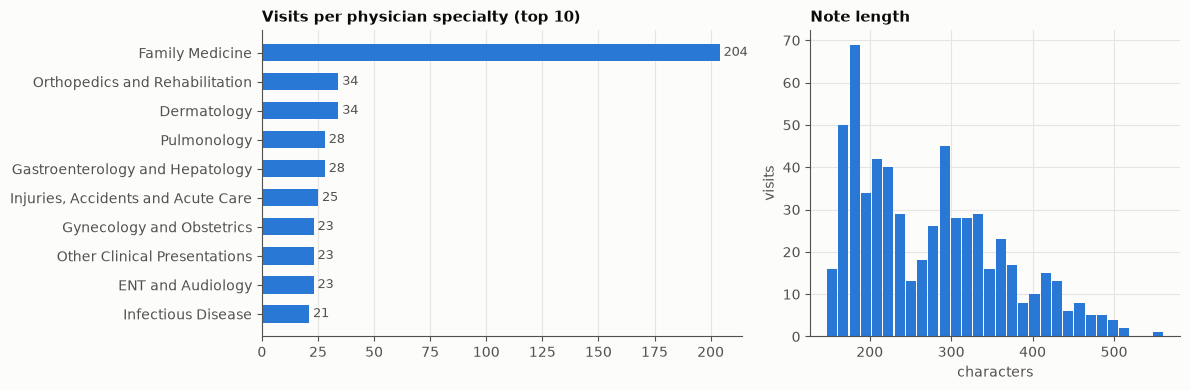

In [2]:
print(f"{len(visits)} visits, {visits.visit_id.nunique()} unique; annotated: {len(gold)}, not annotated: {len(visits) - len(gold)}")
note_len = visits.note_text.str.len()
print(f"note length (characters): median {note_len.median():.0f}, max {note_len.max()}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.3, 1]})
top = visits.physician_specialty.value_counts().head(10)
barh(a1, top.index, top.values)
a1.set_title("Visits per physician specialty (top 10)")
a2.hist(note_len, bins=30, color=BLUE, rwidth=0.9)
a2.set_title("Note length")
a2.set_xlabel("characters"); a2.set_ylabel("visits")
plt.tight_layout(); plt.show()

**Choice →** notes are short (a few hundred characters), so the **whole note goes into every prompt** — no chunking
or retrieval is needed. Visits come from many specialties, so the system cannot be limited to one clinical area.

## 2. Do the physicians agree? (choosing the gold standard)

visits where all 3 physicians gave exactly the same codes: 409/510 (80%)


,pair,exact-code F1
0,DR_A vs DR_B,0.961
1,DR_A vs DR_C,0.944
2,DR_B vs DR_C,0.941


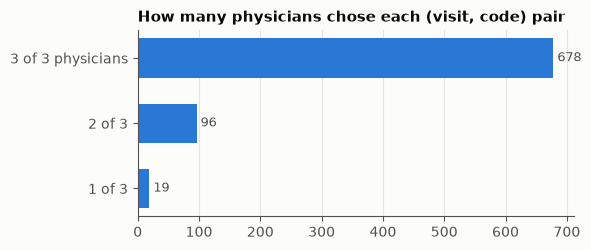

In [3]:
def f1(a, b):
    tp = len(a & b)
    return 2 * tp / (len(a) + len(b)) if (a or b) else 1.0

identical = sum(len({frozenset(s) for s in v.values()}) == 1 for v in by_annotator.values())
print(f"visits where all 3 physicians gave exactly the same codes: {identical}/{len(by_annotator)} ({identical/len(by_annotator):.0%})")

pairs = []
for a, b in combinations(["DR_A", "DR_B", "DR_C"], 2):
    tp = sum(len(v[a] & v[b]) for v in by_annotator.values())
    n = sum(len(v[a]) + len(v[b]) for v in by_annotator.values())
    pairs.append({"pair": f"{a} vs {b}", "exact-code F1": round(2 * tp / n, 3)})
display(pd.DataFrame(pairs))

votes = Counter()
for v in by_annotator.values():
    for c in set().union(*v.values()):
        votes[sum(c in s for s in v.values())] += 1
fig, ax = plt.subplots(figsize=(6, 2.6))
barh(ax, ["3 of 3 physicians", "2 of 3", "1 of 3"], [votes[3], votes[2], votes[1]])
ax.set_title("How many physicians chose each (visit, code) pair")
plt.tight_layout(); plt.show()

**Choice →** agreement is high and most codes are chosen by all three physicians, so the **majority vote (≥ 2 of 3)**
is a reliable gold standard; the pairwise physician F1 is the **human ceiling** for the system.

## 3. How many codes per visit?

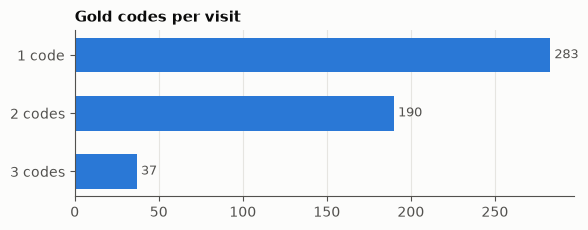

In [4]:
per_visit = Counter(len(g) for g in gold.values())
fig, ax = plt.subplots(figsize=(6, 2.4))
barh(ax, [f"{k} code{'s' if k > 1 else ''}" for k in sorted(per_visit)], [per_visit[k] for k in sorted(per_visit)])
ax.set_title("Gold codes per visit")
plt.tight_layout(); plt.show()

**Choice →** almost half of the visits have 2–3 diagnoses, so the output is a **list of codes per visit**: the
pipeline first extracts every diagnosis and then codes each one; evaluation is **per visit, multi-label**
(precision / recall / F1 over code sets).

## 4. The code distribution is a long tail

493 different gold codes for 510 visits; 282 of them appear only once
test gold codes that never appear in dev: 428/553 (77%)


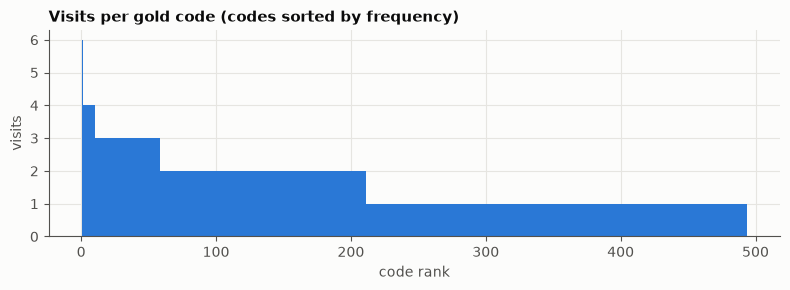

In [5]:
freq = Counter(c for g in gold.values() for c in g)
print(f"{len(freq)} different gold codes for {len(gold)} visits; {sum(v == 1 for v in freq.values())} of them appear only once")
dev_codes = set().union(*(gold[v] for v in splits["dev"]))
test_codes = [c for v in splits["test"] for c in gold[v]]
unseen = sum(c not in dev_codes for c in test_codes)
print(f"test gold codes that never appear in dev: {unseen}/{len(test_codes)} ({unseen/len(test_codes):.0%})")

fig, ax = plt.subplots(figsize=(8, 3))
counts = sorted(freq.values(), reverse=True)
ax.bar(range(1, len(counts) + 1), counts, color=BLUE, width=1.0)
ax.set_title("Visits per gold code (codes sorted by frequency)")
ax.set_xlabel("code rank"); ax.set_ylabel("visits")
plt.tight_layout(); plt.show()

**Choice →** most codes appear once or twice, and most test codes never appear in the development visits. A classifier
trained on these labels could not learn them, so the system is **zero-shot over the full official catalog**: no
training, the model reasons over ICD-10-CM descriptions instead. "Seen vs unseen" recall is reported separately.

## 5. Gold codes span the whole classification

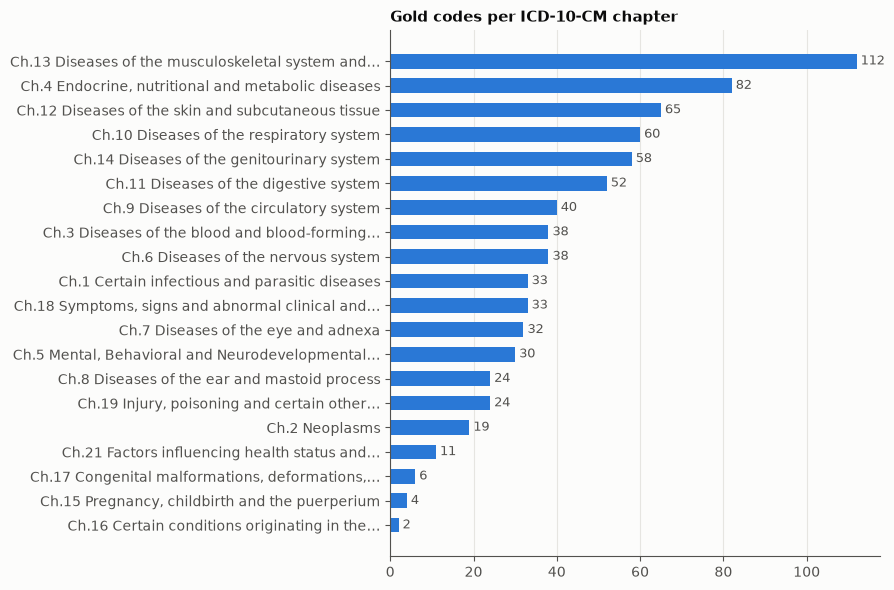

20 of 22 chapters are used by the gold codes


In [6]:
by_chapter = Counter(cat.codes[c].ancestor("chapter").id for g in gold.values() for c in g if cat.is_billable(c))
items = by_chapter.most_common()
short = lambda d: d if len(d) <= 45 else d[:44].rsplit(' ', 1)[0] + '…'
labels = [f"Ch.{ch[2:]} {short(cat.nodes[ch].desc.split(' (')[0])}" for ch, _ in items]
fig, ax = plt.subplots(figsize=(9, 6))
barh(ax, labels, [n for _, n in items])
ax.set_title("Gold codes per ICD-10-CM chapter")
plt.tight_layout(); plt.show()
print(f"{len(items)} of {len(cat.chapters)} chapters are used by the gold codes")

**Choice →** gold codes come from almost every chapter, so the system must navigate the **entire hierarchy** — the first
step is choosing among all 22 chapters (each shown with its section titles), not a pre-selected shortlist.

## 6. Hierarchy sizes: why the category step is conditional (`MAX_CODES = 100`)

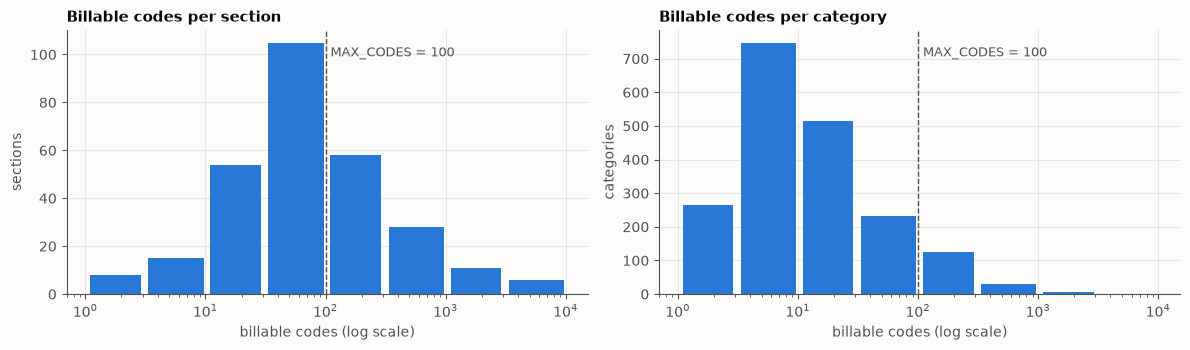

74,955 billable codes; 285 sections, 1,921 categories
sections with > 100 codes: 103/285 (36%); largest: 5,118
gold codes (all annotated visits) whose section has > 100 codes (category step needed): 365/763 (48%)


In [7]:
section_sizes = [s.n_codes for s in cat.sections]
category_sizes = [c.n_codes for s in cat.sections for c in s.children]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for ax, sizes, name in [(axes[0], section_sizes, "section"), (axes[1], category_sizes, "category")]:
    bins = [1, 3, 10, 30, 100, 300, 1000, 3000, 10000]
    ax.hist(sizes, bins=bins, color=BLUE, rwidth=0.9)
    ax.set_xscale("log")
    ax.axvline(config.MAX_CODES, color=INK2, linestyle="--", linewidth=1)
    ax.text(config.MAX_CODES * 1.1, ax.get_ylim()[1] * 0.9, f"MAX_CODES = {config.MAX_CODES}", color=INK2, fontsize=9)
    ax.set_title(f"Billable codes per {name}"); ax.set_xlabel("billable codes (log scale)"); ax.set_ylabel("sections" if name == "section" else "categories")
plt.tight_layout(); plt.show()

big = sum(n > config.MAX_CODES for n in section_sizes)
print(f"{len(cat.codes):,} billable codes; {len(cat.sections)} sections, {len(category_sizes):,} categories")
print(f"sections with > {config.MAX_CODES} codes: {big}/{len(section_sizes)} ({big/len(section_sizes):.0%}); largest: {max(section_sizes):,}")
gold_codes = [c for g in gold.values() for c in g if cat.is_billable(c)]
in_big = sum(cat.codes[c].ancestor("section").n_codes > config.MAX_CODES for c in gold_codes)
print(f"gold codes (all annotated visits) whose section has > {config.MAX_CODES} codes (category step needed): {in_big}/{len(gold_codes)} ({in_big/len(gold_codes):.0%})")

**Choice →** most sections are small enough to show all their codes to the model at once, but some (injuries,
musculoskeletal) hold thousands of codes, mostly from 7th-character extensions. So the category step runs **only
when the selected sections contain more than `MAX_CODES` codes**, and repeats one level deeper if needed — the
final list is never silently truncated.

## 7. Which ICD-10-CM release?

In [8]:
dates = pd.to_datetime(visits.visit_date)
print(f"visit dates: {dates.min().date()} to {dates.max().date()}  ->  US fiscal year 2027 (Oct 1, 2026 - Sep 30, 2027)")
rows = []
for code_, n in annotations.icd10cm_code.value_counts().items():
    if not cat.is_billable(code_):
        node = cat.nodes.get(code_)
        rows.append({"annotated code": code_, "annotation rows": n,
                     "status in FY2027": f"{node.kind} (has more specific child codes)" if node else "not in FY2027"})
display(pd.DataFrame(rows))

visit dates: 2026-10-01 to 2027-09-30  ->  US fiscal year 2027 (Oct 1, 2026 - Sep 30, 2027)


,annotated code,annotation rows,status in FY2027
0,M13.9,11,not in FY2027
1,I31.3,6,subcategory (has more specific child codes)
2,G35,6,category (has more specific child codes)
3,R76.8,3,subcategory (has more specific child codes)
4,M72.2,3,subcategory (has more specific child codes)
5,I42.0,3,subcategory (has more specific child codes)
6,I47.1,1,subcategory (has more specific child codes)


**Choice →** the visit dates fall exactly in **FY2027**, so the FY2027 Tabular XML is used. A few annotated codes are
not billable in FY2027 (they became parent codes or were removed); the system only outputs billable codes, so these
are counted as misses and reported as "unreachable".

## 8. Where are codes lost? (test results, same 100 visits)

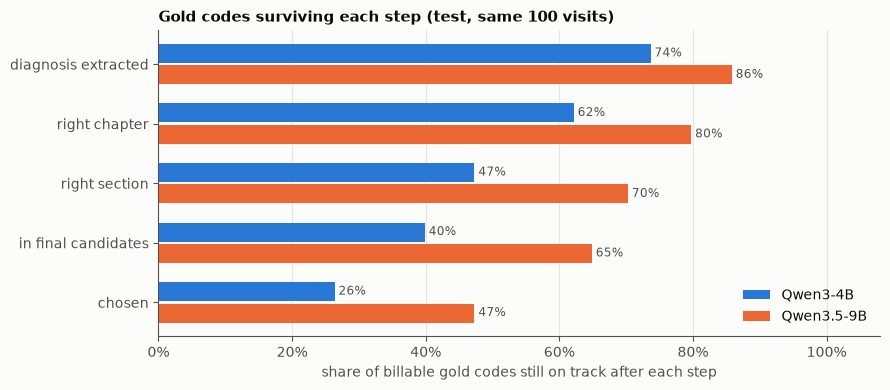

In [9]:
def funnel(run):
    """Follow each billable gold code through the steps, using the diagnosis it was linked to by the eval judge."""
    results = [json.loads(l) for l in open(ROOT / "runs" / f"{run}.jsonl")]
    match = json.loads((ROOT / "runs" / f"{run}_match.json").read_text())
    c = Counter()
    for r in results:
        for code_ in gold[r["visit_id"]]:
            if not cat.is_billable(code_):
                continue
            c["gold codes"] += 1
            i = match[f"{r['visit_id']}|{code_}"]
            if i < 0:
                continue
            t, node = r["trace"][i], cat.codes[code_]
            c["diagnosis extracted"] += 1
            if node.ancestor("chapter").id not in t["chapters"]:
                continue
            c["right chapter"] += 1
            if node.ancestor("section").id not in t["sections"]:
                continue
            c["right section"] += 1
            if code_ not in t["candidates"]:
                continue
            c["in final candidates"] += 1
            c["chosen"] += t["code"] == code_
    return c

steps = ["diagnosis extracted", "right chapter", "right section", "in final candidates", "chosen"]
runs = {"Qwen3-4B": ("test100_qwen3_4b", BLUE), "Qwen3.5-9B": ("test100_qwen35_9b", ORANGE)}
fig, ax = plt.subplots(figsize=(9, 4))
h = 0.36
for k, (label, (run, color)) in enumerate(runs.items()):
    c = funnel(run)
    shares = [c[s] / c["gold codes"] for s in steps]
    y = [len(steps) - 1 - i + (h / 2 if k == 0 else -h / 2) for i in range(len(steps))]
    ax.barh(y, shares, height=h - 0.04, color=color, label=label)
    for yi, v in zip(y, shares):
        ax.text(v, yi, f" {v:.0%}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(steps))[::-1], steps)
ax.set_xlim(0, 1.08); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("share of billable gold codes still on track after each step")
ax.set_title("Gold codes surviving each step (test, same 100 visits)")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

**Reading →** with the same pipeline, the larger model keeps far more gold codes at the first steps (extraction and
section choice), which is where Qwen3-4B loses most — mainly Hebrew medical terms it misreads. Once the diagnosis and
section are right, the category narrowing loses little; the remaining gap is the final choice among candidates
(mostly specificity). Full numbers: `EVALUATION.md`.

## 9. Multi-label: precision, recall and F1 by number of gold codes per visit

visits  precision  recall     F1
model                                         
Qwen3-4B   1      58      0.351   0.345  0.348
           2      34      0.257   0.265  0.261
           3       8      0.188   0.250  0.214
Qwen3.5-9B 1      58      0.486   0.586  0.531
           2      34      0.418   0.485  0.449
           3       8      0.320   0.333  0.327

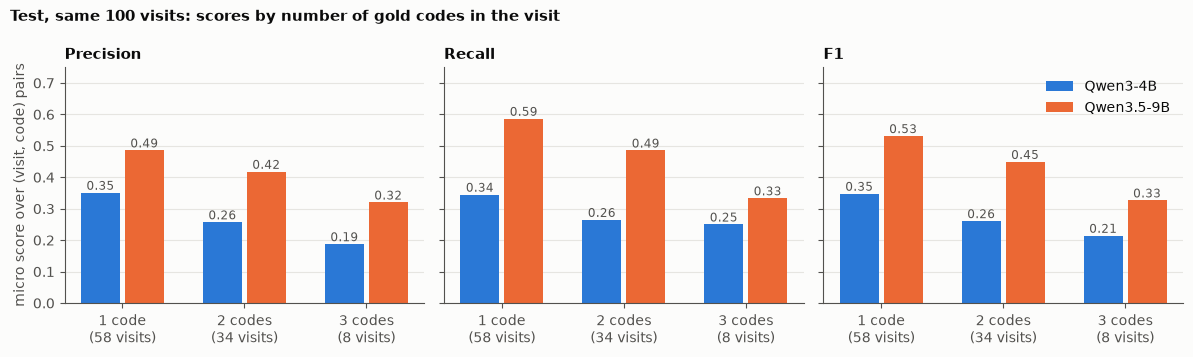

In [10]:
def by_code_count(run):
    """Micro precision / recall / F1 over (visit, code) pairs, for visits with 1, 2 and 3 gold codes."""
    results = [json.loads(l) for l in open(ROOT / "runs" / f"{run}.jsonl")]
    rows = []
    for k in (1, 2, 3):
        rs = [r for r in results if len(gold[r["visit_id"]]) == k]
        tp = sum(len({x["code"] for x in r["predictions"]} & gold[r["visit_id"]]) for r in rs)
        n_pred = sum(len(r["predictions"]) for r in rs)
        n_gold = sum(len(gold[r["visit_id"]]) for r in rs)
        P, R = tp / max(n_pred, 1), tp / max(n_gold, 1)
        rows.append({"gold codes in visit": k, "visits": len(rs), "precision": P, "recall": R,
                     "F1": 2 * P * R / max(P + R, 1e-9)})
    return pd.DataFrame(rows).set_index("gold codes in visit")

tables = {label: by_code_count(run) for label, (run, _) in runs.items()}
display(pd.concat(tables, names=["model", None]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
x = [1, 2, 3]
w = 0.36
for ax, metric in zip(axes, ["precision", "recall", "F1"]):
    for k, (label, (run, color)) in enumerate(runs.items()):
        vals = tables[label][metric].tolist()
        xs = [xi + (-w / 2 if k == 0 else w / 2) for xi in x]
        ax.bar(xs, vals, width=w - 0.04, color=color, label=label)
        for xi, v in zip(xs, vals):
            ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5, color=INK2)
    n = tables[next(iter(tables))]["visits"].tolist()
    ax.set_xticks(x, [f"{k} code{'s' if k > 1 else ''}\n({v} visits)" for k, v in zip(x, n)])
    ax.set_title(metric.capitalize() if metric != "F1" else "F1")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 0.75)
axes[0].set_ylabel("micro score over (visit, code) pairs")
axes[2].legend(loc="upper right", frameon=False)
fig.suptitle("Test, same 100 visits: scores by number of gold codes in the visit", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

**Reading →** both models score lower as visits get more diagnoses: each extra diagnosis is another chance to miss
one, and errors compound. Qwen3.5-9B is better at every size. Only 8 test visits have 3 gold codes, so that group is
noisy. Per-visit averages, exact set match and "all gold codes found" are in `EVALUATION.md`.

### How many of each visit's gold codes were found?

visits  all found  some found  none found
model                                                  
Qwen3-4B   1      58         20           0          38
           2      34          1          16          17
           3       8          0           6           2
Qwen3.5-9B 1      58         34           0          24
           2      34          8          17           9
           3       8          0           7           1

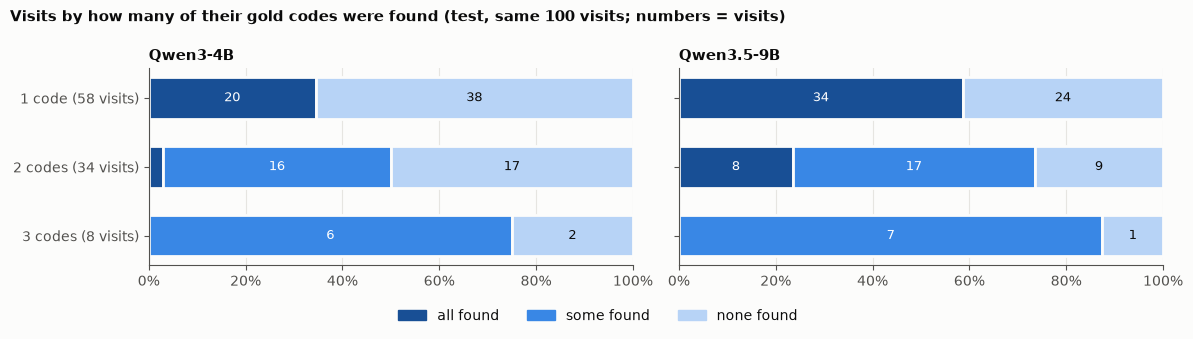

In [11]:
# One hue, dark -> light, for the ordered outcomes all / some / none (blue ramp steps 600 / 400 / 150)
OUTCOMES = [("all found", "#184f95", "white"), ("some found", "#3987e5", "white"), ("none found", "#b7d3f6", INK)]

def found_counts(run):
    results = [json.loads(l) for l in open(ROOT / "runs" / f"{run}.jsonl")]
    rows = []
    for k in (1, 2, 3):
        hits = [len({x["code"] for x in r["predictions"]} & gold[r["visit_id"]]) for r in results
                if len(gold[r["visit_id"]]) == k]
        rows.append({"gold codes in visit": k, "visits": len(hits), "all found": sum(h == k for h in hits),
                     "some found": sum(0 < h < k for h in hits), "none found": sum(h == 0 for h in hits)})
    return pd.DataFrame(rows).set_index("gold codes in visit")

found = {label: found_counts(run) for label, (run, _) in runs.items()}
display(pd.concat(found, names=["model", None]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, (label, df) in zip(axes, found.items()):
    for row_i, (k, row) in enumerate(df.iterrows()):
        y, left = 2 - row_i, 0
        for name, color, text_color in OUTCOMES:
            share = row[name] / row["visits"]
            if share:
                ax.barh(y, share, left=left, color=color, height=0.6, edgecolor="#fcfcfb", linewidth=2)
                if share > 0.06:
                    ax.text(left + share / 2, y, str(row[name]), ha="center", va="center", fontsize=9, color=text_color)
            left += share
    ax.set_yticks([2, 1, 0], [f"{k} code{'s' if k > 1 else ''} ({n} visits)" for k, n in zip(df.index, df["visits"])])
    ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title(label)
handles = [plt.matplotlib.patches.Patch(color=c, label=n) for n, c, _ in OUTCOMES]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Visits by how many of their gold codes were found (test, same 100 visits; numbers = visits)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

**Reading →** for visits with 2–3 gold codes, the most common outcome is *some* codes found: the system usually gets
at least one problem right but rarely all of them. No 3-code visit is coded completely by either model. ("All found"
can still include extra, wrong codes; exact set match is in `EVALUATION.md`.)